In [2]:
from anemone.experiment import *
import matplotlib.pyplot as plt
import numpy as np

In [3]:
lp = Loop.square(25)

In [4]:
rx = Receiver()

In [5]:
class Forward:
    def __init__(self, source, receiver, frequency, tolerance=None):
        self.source = source
        self.receiver = receiver
        self.freq = frequency
        self.rmin = self.source.min_horizontal_distance(self.receiver)
        self.rmax = self.source.max_horizontal_distance(self.receiver)
        self.srcz = torch.tensor([source.z[0]], dtype=torch.float64)
        self.rz = self.receiver.z
        self.pfield_dz = torch.abs(self.srcz-self.rz)
        self.sfield_dz = torch.abs(self.srcz)+torch.abs(self.rz)
        self.device = torch.device('cpu')
        self.tolerance=tolerance

    @property
    def omega(self):
        return c.twopi*self.freq
    
    def forward(self):
        def wvlngth_integrand(wave_length):
            """ Hz from horizontal electric dipole. """
            lmb = wave_length[None, :]
            tmp_u0 = u0(self.omega, lmb)
            intg = torch.exp(-tmp_u0*self.pfield_dz)+rte(self.sigma, self.thick, self.omega, lmb)*torch.exp(-tmp_u0*self.sfield_dz)
            intg *= lmb**2 / tmp_u0
            return torch.squeeze(intg/c.fourpi)
        
        hkl1 = Hankel(wvlngth_integrand, 1, range=(self.rmin, self.rmax), device=self.device, tolerance=self.tolerance)
        res = integrate_around_loop(self.source, self.receiver, hkl1)
        return res



    def __call__(self, sigma, thickness):
        if isinstance(sigma, np.ndarray): sigma = torch.from_numpy(sigma)
        if isinstance(thickness, np.ndarray): thickness = torch.from_numpy(thickness)
        self.sigma = (sigma     + 0j).to(self.device)[...,None]
        self.thick = (thickness + 0j).to(self.device)[...,None]
        return self.forward().real*c.mu0

In [95]:
class Forward2:
    def __init__(self, source, receiver, frequency, tolerance=None):
        self.source = source
        self.receiver = receiver
        self.freq = frequency
        self.rmin = self.source.min_horizontal_distance(self.receiver)
        if self.rmin==0: self.rmin = 1e-2
        self.rmax = self.source.max_horizontal_distance(self.receiver)
        self.srcz = torch.tensor([source.z[0]], dtype=torch.float64)
        self.rz = self.receiver.z.flatten()
        self.pfield_dz = torch.abs(self.srcz-self.rz)[0]
        self.sfield_dz = torch.abs(self.srcz)+torch.abs(self.rz)[0]
        self.device = torch.device('cpu')
        self.tolerance=tolerance        

    @property
    def omega(self):
        return c.twopi*self.freq
    
    def forward(self):
        def wvlngth_integrand(wave_length):
            """ Hz from horizontal electric dipole. """
            lmb = wave_length[None, :]
            tmp_u0 = u0(self.omega, lmb)
            cRTE = rte(self.sigma, self.thick, self.omega, lmb)
            intg = torch.exp(-tmp_u0*self.pfield_dz)+rte(self.sigma, self.thick, self.omega, lmb)*torch.exp(-tmp_u0*self.sfield_dz)
            intg *= lmb**2 / tmp_u0
            return torch.squeeze(intg/c.fourpi)
        
        hkl1 = Hankel(wvlngth_integrand, 1, smp_per_decade=24)
        r,HR = hkl1.range(self.rmin, self.rmax)
        sofr = s_of_r2(self.source, self.receiver, r)
        return - torch.einsum('...i,...i->...', HR, sofr), sofr, r



    def __call__(self, sigma, thickness):
        if isinstance(sigma, np.ndarray): sigma = torch.from_numpy(sigma)
        if isinstance(thickness, np.ndarray): thickness = torch.from_numpy(thickness)
        self.sigma = (sigma     + 0j).to(self.device)[...,None]
        self.thick = (thickness + 0j).to(self.device)[...,None]
        return self.forward()#.real*c.mu0

In [96]:
fwr = Forward(lp, rx, 2000)
fwr2 = Forward2(lp, rx, 2000)

In [97]:
class Receiver:
    def __init__(self, x=0., y=0., z=0., grid=True) -> None:
        self.x = tc.tensor(x, dtype=tc.float64)
        self.y = tc.tensor(y, dtype=tc.float64)
        self.z = tc.tensor(z, dtype=tc.float64)
        
        if grid:
            self.grid()
        else:
            npoints = max(len(self.x), len(self.y),len(self.z))
            if len(self.x)==1: self.x = tc.ones(npoints)*self.x
            if len(self.y)==1: self.y = tc.ones(npoints)*self.y
            if len(self.z)==1: self.z = tc.ones(npoints)*self.z

    def grid(self):
        X,Y,Z = tc.meshgrid(self.x, self.y, self.z, indexing='ij')
        self.x = X.squeeze()
        self.y = Y.squeeze()
        self.z = Z.squeeze()
        self.shp = X.shape#+(3,)
        return self
    
    @property
    def xyz(self):
        return tc.squeeze(tc.moveaxis(tc.stack((
                            self.x.flatten(), 
                            self.y.flatten(), 
                            self.z.flatten())), 0, -1))

    def __len__(self):
        return self.x.numel()

In [98]:
def s_of_r2(self, rx, R):
    R = torch.tensor(R, dtype=torch.float64)
    dR_alpha = torch.sqrt(R[1]/R[0])
    R_edge1 = (R/dR_alpha)
    R_edge2 = (R*dR_alpha)

    rx_xyz = rx.xyz
    if len(rx_xyz.shape)==1:
        s = torch.zeros(R.shape, dtype=torch.complex128)
    else:
        s = torch.zeros(rx_xyz.shape[:-1]+R.shape, dtype=torch.complex128)
        R_edge1 = R_edge1[None, :]
        R_edge2 = R_edge2[None, :]*torch.ones_like(rx_xyz[..., 0])[:, None]
    
    lp_xyz = self.xyz[:, None] - rx_xyz[None, :]
    for i in range(len(self)-1):
        Rz,iRz = getRz(lp_xyz[i], lp_xyz[i+1])
        p1 = torch.einsum('...ij,...j->...i', Rz, lp_xyz[i])
        p2 = torch.einsum('...ij,...j->...i', Rz, lp_xyz[i+1])
        r_perp = p1[..., 1]

        p2norm = torch.sqrt(p2[..., 0]**2 + p2[..., 1]**2)
        s_norm = torch.abs(p2[..., 0]-p1[..., 0])

        if len(rx_xyz.shape)>1:
            r_perp = r_perp[:, None]*torch.ones_like(R)
            p2norm = p2norm[:, None]*torch.ones_like(R)
            s_norm = s_norm[:, None]*torch.ones_like(R)
        ds = torch.nan_to_num(torch.sqrt(R_edge2**2 - r_perp**2) - torch.sqrt(R_edge1**2 - r_perp**2))
        ds[R_edge2>p2norm] = 0.
        ds[R_edge1<r_perp] = 0.
        
        ds_sum = torch.nansum(ds, axis=-1, keepdims=True)
        ds_sum[ds_sum==0] = torch.inf
        ds *= s_norm/ds_sum
        s += (r_perp*ds)/R
    return s        

In [99]:
def s_of_r2(self, rx, R):
    R = torch.tensor(R, dtype=torch.float64)
    dR_alpha = torch.sqrt(R[1]/R[0])
    R_edge1 = (R/dR_alpha)
    R_edge2 = (R*dR_alpha)
    dR = torch.from_numpy(np.gradient(R.numpy()))

    rx_xyz = rx.xyz
    if len(rx_xyz.shape)==1:
        s = torch.zeros(R.shape, dtype=torch.complex128)
    else:
        s = torch.zeros(rx_xyz.shape[:-1]+R.shape, dtype=torch.complex128)
        R_edge1 = R_edge1[None, :]
        R_edge2 = R_edge2[None, :]*torch.ones_like(rx_xyz[..., 0])[:, None]
        R_ = R[None, :]*torch.ones_like(rx_xyz[..., 0])[:, None]
        dR = dR[None, :]*torch.ones_like(rx_xyz[..., 0])[:, None]
    
    lp_xyz = self.xyz[:, None] - rx_xyz[None, :]
    for i in range(len(self)-1):
        Rz,iRz = getRz(lp_xyz[i], lp_xyz[i+1])
        p1 = torch.einsum('...ij,...j->...i', Rz, lp_xyz[i])
        p2 = torch.einsum('...ij,...j->...i', Rz, lp_xyz[i+1])
        r_perp = p1[..., 1]
        
        
        Rp1 = torch.sqrt(p1[..., 0]**2 + p1[..., 1]**2)
        Rp2 = torch.sqrt(p2[..., 0]**2 + p2[..., 1]**2)
        
        s_norm = torch.abs(p2[..., 0]-p1[..., 0])

        if len(rx_xyz.shape)>1:
            r_perp = r_perp[:, None]*torch.ones_like(R)
            Rp2 = Rp2[:, None]*torch.ones_like(R)
            Rp1 = Rp1[:, None]*torch.ones_like(R)
            s_norm = s_norm[:, None]*torch.ones_like(R)

        ds = torch.zeros_like(R_)
        ds[(R_>=r_perp)*(R_<=torch.abs(Rp1))] += 1
        mask = (R_>=r_perp)*(R_<=torch.abs(Rp2))
        ds[mask] += -torch.sign(Rp1[mask])*torch.sign(Rp2[mask])
        ds *= dR
        
        
        ds_sum = torch.nansum(ds, axis=-1, keepdims=True)
        ds_sum[ds_sum==0] = torch.inf
        ds *= s_norm/ds_sum
        s += torch.nan_to_num((r_perp*ds)/R_)
    return s

In [100]:
def s_of_r2(self, rx, R):
    R = torch.tensor(R, dtype=torch.float64)
    dR_alpha = torch.sqrt(R[1]/R[0])
    R_edge1 = (R/dR_alpha)
    R_edge2 = (R*dR_alpha)
    dR = torch.from_numpy(np.gradient(R.numpy()))

    rx_xyz = rx.xyz
    if len(rx_xyz.shape)==1:
        s = torch.zeros(R.shape, dtype=torch.complex128)
    else:
        s = torch.zeros(rx_xyz.shape[:-1]+R.shape, dtype=torch.complex128)
        R_edge1 = R_edge1[None, :]
        R_edge2 = R_edge2[None, :]*torch.ones_like(rx_xyz[..., 0])[:, None]
        R_ = R[None, :]*torch.ones_like(rx_xyz[..., 0])[:, None]
        dR = dR[None, :]*torch.ones_like(rx_xyz[..., 0])[:, None]
    
    lp_xyz = self.xyz[:, None] - rx_xyz[None, :]
    for i in range(1):
        Rz,iRz = getRz(lp_xyz[i], lp_xyz[i+1])
        p1 = torch.einsum('...ij,...j->...i', Rz, lp_xyz[i])
        p2 = torch.einsum('...ij,...j->...i', Rz, lp_xyz[i+1])
        y1 = p1[..., 1]
        r_perp = torch.abs(y1)

        x1 = p1[..., 0]
        x2 = p2[..., 0]
        
        
        Rp1 = torch.sqrt(p1[..., 0]**2 + p1[..., 1]**2)
        Rp2 = torch.sqrt(p2[..., 0]**2 + p2[..., 1]**2)
        
        s_norm = torch.abs(p2[..., 0]-p1[..., 0])

        if len(rx_xyz.shape)>1:
            r_perp = r_perp[:, None]*torch.ones_like(R)
            Rp2 = Rp2[:, None]*torch.ones_like(R)
            Rp1 = Rp1[:, None]*torch.ones_like(R)
            s_norm = s_norm[:, None]*torch.ones_like(R)
            x1 = x1[:, None]*torch.ones_like(R)
            x2 = x2[:, None]*torch.ones_like(R)
            y1 = y1[:, None]*torch.ones_like(R)

        ds = torch.zeros_like(R_)
        # scenario 1 0<sign(p1[...,0])<sign(p2[...,0])
        mask = (R_>=r_perp)*(R_>=Rp1)*(R_<=Rp2)*(x1>=0)*(x2>=0)
        ds[mask] += 1

        # scenario 2 sign(x1)<0<sign(x2)
        mask = (R_>=r_perp)*(R_<=Rp1)*(x1<=0)*(x2>=0)
        ds[mask] += 1

        mask = (R_>=r_perp)*(R_<=Rp2)*(x2>=0)*(x1<=0)
        ds[mask] += 1

        # scenario 3 sign(x1)<sign(x2)<0
        mask = (R_>=r_perp)*(R_>=Rp1)*(R_<=Rp2)*(x1<=0)*(x2<=0)
        ds[mask] += 1
        ds *= dR

        mask = (R_>=r_perp)*(R_<=Rp2)*(x2>=0)*(x2<=0)
        ds[mask] += 1

        mask = (R_>=r_perp)*(R_<=Rp1)*(x1>=0)*(x2<=0)
        ds[mask] += 1        
        
        ds_sum = torch.nansum(ds, axis=-1, keepdims=True)
        ds_sum[ds_sum==0] = torch.inf
        ds *= s_norm/ds_sum
        s += torch.nan_to_num((y1*ds)/R_)
    return s

In [101]:
def s_of_r2(self, rx, R):
    R = torch.tensor(R, dtype=torch.float64)
    dR_alpha = torch.sqrt(R[1]/R[0])
    R_edge1 = (R/dR_alpha)
    R_edge2 = (R*dR_alpha)
    dR = torch.from_numpy(np.gradient(R.numpy()))

    rx_xyz = rx.xyz
    if len(rx_xyz.shape)==1:
        s = torch.zeros(R.shape, dtype=torch.complex128)
    else:
        s = torch.zeros(rx_xyz.shape[:-1]+R.shape, dtype=torch.complex128)
        R_edge1 = R_edge1[None, :]*torch.ones_like(rx_xyz[..., 0])[:, None]
        R_edge2 = R_edge2[None, :]*torch.ones_like(rx_xyz[..., 0])[:, None]
        R_ = R[None, :]*torch.ones_like(rx_xyz[..., 0])[:, None]
        dR = dR[None, :]*torch.ones_like(rx_xyz[..., 0])[:, None]
    
    lp_xyz = self.xyz[:, None] - rx_xyz[None, :]
    # for i in range(len(self)-1):
    for i in range(1):

        Rz,iRz = getRz(lp_xyz[i], lp_xyz[i+1])
        p1 = torch.einsum('...ij,...j->...i', Rz, lp_xyz[i])
        p2 = torch.einsum('...ij,...j->...i', Rz, lp_xyz[i+1])
        y1 = p1[..., 1]
        r_perp = torch.abs(y1)

        x1 = p1[..., 0]
        x2 = p2[..., 0]
        
        
        Rp1 = torch.sqrt(p1[..., 0]**2 + p1[..., 1]**2)
        Rp2 = torch.sqrt(p2[..., 0]**2 + p2[..., 1]**2)
        
        s_norm = torch.abs(p2[..., 0]-p1[..., 0])

        if len(rx_xyz.shape)>1:
            r_perp = r_perp[:, None]*torch.ones_like(R)
            Rp2 = Rp2[:, None]*torch.ones_like(R)
            Rp1 = Rp1[:, None]*torch.ones_like(R)
            s_norm = s_norm[:, None]*torch.ones_like(R)
            x1 = x1[:, None]*torch.ones_like(R)
            x2 = x2[:, None]*torch.ones_like(R)
            y1 = y1[:, None]*torch.ones_like(R)

        ds = torch.zeros_like(R_)
        # scenario 1 0<sign(p1[...,0])<sign(p2[...,0])

        mask_rperp = (R_>=r_perp)
        mask = mask_rperp*(R_>=Rp1)*(R_edge2<=Rp2)*(x1>=0)*(x2>=0)
        ds[mask] += 1


        # scenario 2 sign(x1)<0<sign(x2)
        mask = mask_rperp*(R_edge2<=Rp1)*(x1<=0)*(x2>=0)
        ds[mask] += 1
        mask = mask_rperp*(R_edge2<=Rp2)*(x2>=0)*(x1<=0)
        ds[mask] += 1

        # scenario 3 sign(x1)<sign(x2)<0
        mask = mask_rperp*(R_>=Rp1)*(R_edge2<=Rp2)*(x1<=0)*(x2<=0)
        ds[mask] += 1
        # ds *= dR[mask]
    
        mask = mask_rperp*(R_edge2<=Rp1)*(R_>=Rp2)*(x1<=0)*(x2<=0)
        ds[mask] += 1

        mask = (r_perp>=R_edge1)*(r_perp<=R_edge2)*(x2>=0)*(x1<=0)
        ds[mask] += dR[mask]
        mask = (r_perp>=R_edge1)*(r_perp<=R_edge2)*(x2<=0)*(x1>=0)
        ds[mask] += 1       
        
        ds_sum = torch.sum(ds, axis=-1, keepdims=True)
        # ds_sum[ds_sum==0] = torch.inf
        ds *= s_norm/ds_sum
        s += torch.nan_to_num((y1*ds)/R_)
    return s

In [102]:
#working sort of...
def s_of_r2(self, rx, R):
    R = torch.tensor(R, dtype=torch.float64)
    dR_alpha = torch.sqrt(R[1]/R[0])
    R_edge1 = (R/dR_alpha)
    R_edge2 = (R*dR_alpha)
    dR = torch.from_numpy(np.gradient(R.numpy()))

    rx_xyz = rx.xyz
    if len(rx_xyz.shape)==1:
        s = torch.zeros(R.shape, dtype=torch.complex128)
    else:
        s = torch.zeros(rx_xyz.shape[:-1]+R.shape, dtype=torch.complex128)
        R_edge1 = R_edge1[None, :]*torch.ones_like(rx_xyz[..., 0])[:, None]
        R_edge2 = R_edge2[None, :]*torch.ones_like(rx_xyz[..., 0])[:, None]
        R_ = R[None, :]*torch.ones_like(rx_xyz[..., 0])[:, None]
        dR = dR[None, :]*torch.ones_like(rx_xyz[..., 0])[:, None]
    
    lp_xyz = self.xyz[:, None] - rx_xyz[None, :]
    
    for i in range(len(self)-1):
    
        Rz,iRz = getRz(lp_xyz[i], lp_xyz[i+1])
        p1 = torch.einsum('...ij,...j->...i', Rz, lp_xyz[i])
        p2 = torch.einsum('...ij,...j->...i', Rz, lp_xyz[i+1])
        y1 = p1[..., 1]
        y2 = p2[..., 1]
        r_perp = torch.abs(y1)

        x1 = p1[..., 0]
        x2 = p2[..., 0]
       
        Rp1 = torch.sqrt(p1[..., 0]**2 + p1[..., 1]**2)
        Rp2 = torch.sqrt(p2[..., 0]**2 + p2[..., 1]**2)
        
        s_norm = torch.abs(p2[..., 0]-p1[..., 0])

        if len(rx_xyz.shape)>1:
            r_perp = r_perp[:, None]*torch.ones_like(R)
            Rp2 = Rp2[:, None]*torch.ones_like(R)
            Rp1 = Rp1[:, None]*torch.ones_like(R)
            s_norm = s_norm[:, None]*torch.ones_like(R)
            x1 = x1[:, None]*torch.ones_like(R)
            x2 = x2[:, None]*torch.ones_like(R)
            y1 = y1[:, None]*torch.ones_like(R)

        ds = torch.zeros_like(R_)

        ds_comp = R_ / r_perp

        maskx = (x1>=0)*(x2>=0)
        maskr = (R_edge2>=Rp1)*(R_edge1<=Rp2)
        ds[maskx*maskr] += 1

        # these ones are ok...
        maskx = (x1<=0)*(x2>0)
        maskr = (R_edge2>r_perp)*(R_edge1<=Rp1)
        ds[maskx*maskr] += 1
        maskr = (R_edge2>r_perp)*(R_edge1<=Rp2)
        ds[maskx*maskr] += 1


        maskx = (x1<=0)*(x2<=0)
        maskr = (R_edge2>=Rp2)*(R_edge1<=Rp1)
        ds[maskx*maskr] += 1

        ds *= (dR/r_perp)

        
        ds_sum = torch.sum(ds, axis=-1, keepdims=True)
        # ds_sum[ds_sum==0] = torch.inf
        ds *= s_norm/ds_sum
        s += torch.nan_to_num((y1*ds)/R_)
    return s

In [103]:
def s_of_r2(self, rx, R):
    R = torch.tensor(R, dtype=torch.float64)
    dR_alpha = torch.sqrt(R[1]/R[0])
    R_edge1 = (R/dR_alpha)
    R_edge2 = (R*dR_alpha)
    dR = torch.from_numpy(np.gradient(R.numpy()))

    rx_xyz = rx.xyz
    if len(rx_xyz.shape)==1:
        s = torch.zeros(R.shape, dtype=torch.complex128)
    else:
        s = torch.zeros(rx_xyz.shape[:-1]+R.shape, dtype=torch.complex128)
        R_edge1 = R_edge1[None, :]*torch.ones_like(rx_xyz[..., 0])[:, None]
        R_edge2 = R_edge2[None, :]*torch.ones_like(rx_xyz[..., 0])[:, None]
        R_ = R[None, :]*torch.ones_like(rx_xyz[..., 0])[:, None]
        dR = dR[None, :]*torch.ones_like(rx_xyz[..., 0])[:, None]
    
    lp_xyz = self.xyz[:, None] - rx_xyz[None, :]
    
    # for i in range(len(self)-1):
    for i in range(1):
    
        Rz,iRz = getRz(lp_xyz[i], lp_xyz[i+1])
        p1 = torch.einsum('...ij,...j->...i', Rz, lp_xyz[i])
        p2 = torch.einsum('...ij,...j->...i', Rz, lp_xyz[i+1])
        y1 = p1[..., 1]
        y2 = p2[..., 1]
        r_perp = torch.abs(y1)

        x1 = p1[..., 0]
        x2 = p2[..., 0]
       
        Rp1 = torch.sqrt(p1[..., 0]**2 + p1[..., 1]**2)
        Rp2 = torch.sqrt(p2[..., 0]**2 + p2[..., 1]**2)
        
        s_norm = torch.abs(p2[..., 0]-p1[..., 0])

        if len(rx_xyz.shape)>1:
            r_perp = r_perp[:, None]*torch.ones_like(R)
            Rp2 = Rp2[:, None]*torch.ones_like(R)
            Rp1 = Rp1[:, None]*torch.ones_like(R)
            s_norm = s_norm[:, None]*torch.ones_like(R)
            x1 = x1[:, None]*torch.ones_like(R)
            x2 = x2[:, None]*torch.ones_like(R)
            y1 = y1[:, None]*torch.ones_like(R)

        ds = torch.zeros_like(R_)
        #dx_comp = torch.ones_like(R_)

        dx_comp = R_*dR / (R_**2 - r_perp**2)**(1/2)

        maskx = (x1>=0)*(x2>=0)
        maskr = (R_edge2>=Rp1)*(R_edge1<=Rp2)
        ds[maskx*maskr] += dx_comp[maskx*maskr]

        # these ones are ok...
        maskx = (x1<=0)*(x2>0)
        maskr = (R_edge2>r_perp)*(R_edge1<=Rp1)
        ds[maskx*maskr] += dx_comp[maskx*maskr]
        maskr = (R_edge2>r_perp)*(R_edge1<=Rp2)
        ds[maskx*maskr] += dx_comp[maskx*maskr]


        maskx = (x1<=0)*(x2<=0)
        maskr = (R_edge2>=Rp2)*(R_edge1<=Rp1)
        ds[maskx*maskr] += dx_comp[maskx*maskr]

        
        ds_sum = torch.nansum(ds, axis=-1, keepdims=True)
        ds_sum[ds_sum==0] = torch.inf
        ds *= s_norm/ds_sum
        #s += torch.nan_to_num((y1*ds)/R_)
        s += torch.nan_to_num(ds)
    return s

In [104]:
def r_edges(r):
    dR_alpha = torch.sqrt(r[1]/r[0])
    R_edge1 = (r/dR_alpha)
    R_edge2 = (r*dR_alpha)
    return R_edge1, R_edge2

In [105]:
def s_of_r2(self, rx, R):
    R = torch.tensor(R, dtype=torch.float64)
    R_edge1,R_edge2 = r_edges(R)
    dR = R_edge2-R_edge1

    rx_xyz = rx.xyz
    if len(rx_xyz.shape)==1:
        s = torch.zeros(R.shape, dtype=torch.complex128)
    else:
        s = torch.zeros(rx_xyz.shape[:-1]+R.shape, dtype=torch.complex128)
        R_edge1 = R_edge1[None, :]*torch.ones_like(rx_xyz[..., 0])[:, None]
        R_edge2 = R_edge2[None, :]*torch.ones_like(rx_xyz[..., 0])[:, None]
        R_ = R[None, :]*torch.ones_like(rx_xyz[..., 0])[:, None]
        dR = dR[None, :]*torch.ones_like(rx_xyz[..., 0])[:, None]
    
    lp_xyz = self.xyz[:, None] - rx_xyz[None, :]
    
    # for i in range(len(self)-1):
    for i in range(1):
    
        Rz,iRz = getRz(lp_xyz[i], lp_xyz[i+1])
        p1 = torch.einsum('...ij,...j->...i', Rz, lp_xyz[i])
        p2 = torch.einsum('...ij,...j->...i', Rz, lp_xyz[i+1])
        y1 = p1[..., 1]
        y2 = p2[..., 1]
        r_perp = torch.abs(y1)

        x1 = p1[..., 0]
        x2 = p2[..., 0]
       
        Rp1 = torch.sqrt(p1[..., 0]**2 + p1[..., 1]**2)
        Rp2 = torch.sqrt(p2[..., 0]**2 + p2[..., 1]**2)
        
        s_norm = torch.abs(p2[..., 0]-p1[..., 0])

        if len(rx_xyz.shape)>1:
            r_perp = r_perp[:, None]*torch.ones_like(R)
            Rp2 = Rp2[:, None]*torch.ones_like(R)
            Rp1 = Rp1[:, None]*torch.ones_like(R)
            s_norm = s_norm[:, None]*torch.ones_like(R)
            x1 = x1[:, None]*torch.ones_like(R)
            x2 = x2[:, None]*torch.ones_like(R)
            y1 = y1[:, None]*torch.ones_like(R)

        ds = torch.zeros_like(R_)
        dx_comp = torch.ones_like(R_)

        r_perp[r_perp==R_] += 0.02

        dx_comp = R_*dR / torch.sqrt(R_**2 - r_perp**2)
        dx_comp[R_<=r_perp] = 1.
        
        dx_comp[(R_edge2>Rp2)*(R_edge2>Rp1)] = 0        
        #dx_comp = torch.sqrt(R_**2 - r_perp**2)*(R_edge2-R_edge1) / R_
        # dx_comp[R_<r_perp] = 0
        # dx_comp[(R_edge2>Rp2)*(R_edge2>Rp1)] = 0

        # dx_comp *= dR#(R_edge2-R_edge1)

        maskx = (x1>=0)*(x2>0)
        maskr = (R_edge2>=Rp1)*(R_edge1<=Rp2)
        ds[maskx*maskr] += dx_comp[maskx*maskr]
        dx_comp[maskx*maskr] = 0

        # these ones are ok...
        maskx = (x1<0)*(x2>0)
        maskxleft = x1+x2<=0
        # maskr  = (R_edge2>=r_perp)*(R_edge1<=Rp1)
        maskr  = (R_>=r_perp)*(R_<=Rp1)
        ds[maskx*maskxleft*maskr] += dx_comp[maskx*maskxleft*maskr]
        dx_comp[maskx*maskxleft*maskr] = 0
        
        # maskr  = (R_edge2>=r_perp)*(R_edge1<=Rp1)
        # ds[maskx*maskxleft*maskr] += dx_comp[maskx*maskxleft*maskr]
        # dx_comp[maskx*maskxleft*maskr] = 0

        # maskr  = (R_edge2>=r_perp)*(R_edge1<Rp1)
        
        maskxright = x1+x2>0
        maskr = (R_edge2>=r_perp)*(R_edge1<=Rp2)
        ds[maskx*maskxright*maskr] += dx_comp[maskx*maskxright*maskr]
        dx_comp[maskx*maskxright*maskr] = 0




        maskx = (x1<0)*(x2<=0)
        maskr = (R_edge2>=Rp2)*(R_edge1<=Rp1)
        ds[maskx*maskr] += dx_comp[maskx*maskr]
        dx_comp[maskx*maskr] = 0
        
        ds_sum = torch.nansum(ds, axis=-1, keepdims=True)
        # ds_sum[ds_sum==0] = torch.inf
        ds *= s_norm/ds_sum
        # s += torch.nan_to_num((y1*ds/R_))
        s += torch.nan_to_num(ds)
    return s

In [106]:
def s_of_r2(self, rx, R):
    R = torch.tensor(R, dtype=torch.float64)
    dR_alpha = torch.sqrt(R[1]/R[0])
    R_edge1 = (R/dR_alpha)
    R_edge2 = (R*dR_alpha)
    dR = torch.from_numpy(np.gradient(R.numpy()))

    rx_xyz = rx.xyz
    if len(rx_xyz.shape)==1:
        s = torch.zeros(R.shape, dtype=torch.complex128)
        R_ = R
    else:
        s = torch.zeros(rx_xyz.shape[:-1]+R.shape, dtype=torch.complex128)
        R_edge1 = R_edge1[None, :]*torch.ones_like(rx_xyz[..., 0])[:, None]
        R_edge2 = R_edge2[None, :]*torch.ones_like(rx_xyz[..., 0])[:, None]
        R_ = R[None, :]*torch.ones_like(rx_xyz[..., 0])[:, None]
        dR = dR[None, :]*torch.ones_like(rx_xyz[..., 0])[:, None]
    
    lp_xyz = self.xyz[:, None] - rx_xyz[None, :]
    
    for i in range(len(self)-1):
    # for i in range(1):
    
        Rz,iRz = getRz(lp_xyz[i], lp_xyz[i+1])
        p1 = torch.einsum('...ij,...j->...i', Rz, lp_xyz[i])
        p2 = torch.einsum('...ij,...j->...i', Rz, lp_xyz[i+1])
        x1,y1 = p1[..., 0], p1[..., 1]
        x2,y2 = p2[..., 0], p2[..., 1]
        r_perp = torch.abs(y1)
       
        Rp1 = torch.sqrt(x1**2 + y1**2)
        Rp2 = torch.sqrt(x2**2 + y2**2)
        
        s_norm = torch.abs(p2[..., 0]-p1[..., 0])

        if len(rx_xyz.shape)>1:
            r_perp = r_perp[:, None]*torch.ones_like(R)
            Rp2 = Rp2[:, None]*torch.ones_like(R)
            Rp1 = Rp1[:, None]*torch.ones_like(R)
            s_norm = s_norm[:, None]*torch.ones_like(R)
            x1 = x1[:, None]*torch.ones_like(R)
            x2 = x2[:, None]*torch.ones_like(R)
            y1 = y1[:, None]*torch.ones_like(R)

        ds = torch.zeros_like(R_)
        dx_comp = R_*dR / (R_**2 - r_perp**2)**(1/2)
        dx_comp[R_<=r_perp] = 1.
        dx_comp = torch.nan_to_num(dx_comp)

        maskx = (x1>=0)*(x2>=0)
        maskr = (R_edge2>=Rp1)*(R_edge1<=Rp2)

        ds[maskx*maskr] += dx_comp[maskx*maskr]

        maskx = (x1<0)*(x2>0)
        maskxleft = x1+x2<0
        #maskr  = (R_>=r_perp)*(R_<=Rp1)
        maskr = (R_edge2>=r_perp)*(R_edge1<=Rp1)

        # if not (maskx*maskxleft*maskr).any(): print('left side is empty')
        ds[maskx*maskxleft*maskr] += dx_comp[maskx*maskxleft*maskr]
        
        
        maskxright = x1+x2>=0
        maskr = (R_edge2>=r_perp)*(R_edge1<=Rp2)
        if not (maskx*maskxright*maskr).any(): 
            print('right side is empty')
        elif torch.isnan(dx_comp[maskx*maskxright*maskr]).any():
            print(dx_comp[maskx*maskxright*maskr])
        ds[maskx*maskxright*maskr] += dx_comp[maskx*maskxright*maskr]


        maskx = (x1<=0)*(x2<=0)
        maskr = (R_edge2>=Rp2)*(R_edge1<=Rp1)
        # if not (maskx*maskr).any(): print('maskr is empty')
        ds[maskx*maskr] += dx_comp[maskx*maskr]


        ds[...,1:-1] = 0.25*(ds[..., 2:] + ds[..., :-2] + 2*ds[..., 1:-1])


        
        ds_sum = torch.nansum(ds, axis=-1, keepdims=True)
        if ds_sum.sum()==0:
            print('ds==0\tr_perp is ', r_perp[0].item())
        ds *= s_norm/ds_sum
        # s += torch.nan_to_num((y1*ds)/R_)
        # s += torch.nan_to_num(ds)
    return s#.real

In [107]:
def s_of_r2(self, rx, R):
    """almost working"""
    R = torch.tensor(R, dtype=torch.float64)
    dR_alpha = torch.sqrt(R[1]/R[0])
    R_edge1 = (R/dR_alpha)
    R_edge2 = (R*dR_alpha)
    dR = R_edge2-R_edge1
    iR = torch.arange(len(R))
    
    rx_xyz = rx.xyz
    if len(rx_xyz.shape)==1:
        s = torch.zeros(R.shape, dtype=torch.complex128)
        R_ = R
    else:
        s = torch.zeros(rx_xyz.shape[:-1]+R.shape, dtype=torch.complex128)
        R_edge1 = R_edge1[None, :]*torch.ones_like(rx_xyz[..., 0])[:, None]
        R_edge2 = R_edge2[None, :]*torch.ones_like(rx_xyz[..., 0])[:, None]
        R_ = R[None, :]*torch.ones_like(rx_xyz[..., 0])[:, None]
        dR = dR[None, :]*torch.ones_like(rx_xyz[..., 0])[:, None]
        iR = iR[None, :]*torch.ones_like(rx_xyz[..., 0])[:, None]
        R_lb = R_*1.
        R_lb[..., 1:] = R_[..., :-1]
    
    lp_xyz = self.xyz[:, None] - rx_xyz[None, :]
    
    for i in range(len(self)-1):
    
        Rz,iRz = getRz(lp_xyz[i], lp_xyz[i+1])
        p1 = torch.einsum('...ij,...j->...i', Rz, lp_xyz[i])
        p2 = torch.einsum('...ij,...j->...i', Rz, lp_xyz[i+1])
        x1,y1 = p1[..., 0], p1[..., 1]
        x2,y2 = p2[..., 0], p2[..., 1]
        r_perp = torch.abs(y1)
        
       
        Rp1 = torch.sqrt(x1**2 + y1**2)
        Rp2 = torch.sqrt(x2**2 + y2**2)
        
        s_norm = torch.abs(p2[..., 0]-p1[..., 0])

        if len(rx_xyz.shape)>1:
            r_perp = r_perp[:, None]*torch.ones_like(R)
            Rp2 = Rp2[:, None]*torch.ones_like(R)
            Rp1 = Rp1[:, None]*torch.ones_like(R)
            s_norm = s_norm[:, None]*torch.ones_like(R)
            x1 = x1[:, None]*torch.ones_like(R)
            x2 = x2[:, None]*torch.ones_like(R)
            y1 = y1[:, None]*torch.ones_like(R)

        
        rmax = torch.sqrt(r_perp**2+x1**2)
        rmin = r_perp

        cx = np.sqrt(torch.abs(R_**2 - r_perp**2))
        dx = torch.diff(cx, axis=-1, prepend=torch.zeros_like(cx[..., 0:1]))
        # dx = R_*(R_-R_lb) / (R_**2 - r_perp**2)**(1/2)
        dx[R_<r_perp] = 0
        dx[R_>rmax] = 0
        ir1 = torch.searchsorted(R_, rmin)
        ir2 = torch.searchsorted(R_, rmax)-1

        
        dx[ir1==iR]=cx[ir1==iR]
        dx[ir2==iR] += x1[ir2==iR]-cx[ir2==iR]


        ds1 = dx*1.
        ds1 *= torch.abs(x1)/torch.abs(torch.nansum(ds1, axis=-1, keepdims=True))
        Rcomp = (R_**2 - (0.25*ds1)**2)**(1/2)
        ds1 /= R_/Rcomp

        rmax = torch.sqrt(r_perp**2+x2**2)

        cx = np.sqrt(torch.abs(R_**2 - r_perp**2))
        dx = torch.diff(cx, axis=-1, prepend=torch.zeros_like(cx[..., 0:1]))
        # dx = R_*(R_-R_lb) / (R_**2 - r_perp**2)**(1/2)
        dx[R_<r_perp] = 0
        dx[R_>rmax] = 0


        ir1 = torch.searchsorted(R_, rmin)
        ir2 = torch.searchsorted(R_, rmax)-1

        dx[ir1==iR]=(cx[ir1==iR])
        dx[ir2==iR] += x2[ir2==iR]-cx[ir2==iR]


        ds2  = dx*1.
        ds2 *= torch.abs(x2)/torch.abs(torch.nansum(ds2, axis=-1, keepdims=True))
        Rcomp = (R_**2 - (0.25*ds2)**2)**(1/2)
        ds2 /= R_/Rcomp

        ds = ds1 + ds2

        # ds_sum = torch.nansum(ds, axis=-1, keepdims=True)
        # ds *= s_norm/ds_sum
        s += torch.nan_to_num(y1*ds/(R_))
    return s#.real

In [108]:
lp = Loop.square(60)
rxs = Receiver(x=np.linspace(-75, 75, 61), y=np.linspace(-75, 75, 61))
rmin,rmax = lp.min_horizontal_distance(rxs), lp.max_horizontal_distance(rxs)
r = np.geomspace(0.1, rmax, 128)
sofr = s_of_r2(lp, rxs, torch.from_numpy(r))
fwr3 = Forward2(lp, rxs, 2000)

C:\Users\au646858\AppData\Local\Temp\ipykernel_26272\1286983842.py:3: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  R = torch.tensor(R, dtype=torch.float64)


In [109]:
bz = fwr3(np.array([0.1, 0.1]), np.array([40]))[0].real.reshape(fwr3.receiver.shp[:-1])

C:\Users\au646858\AppData\Local\Temp\ipykernel_26272\1286983842.py:3: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  R = torch.tensor(R, dtype=torch.float64)


In [110]:
n_skip = len(r)//16

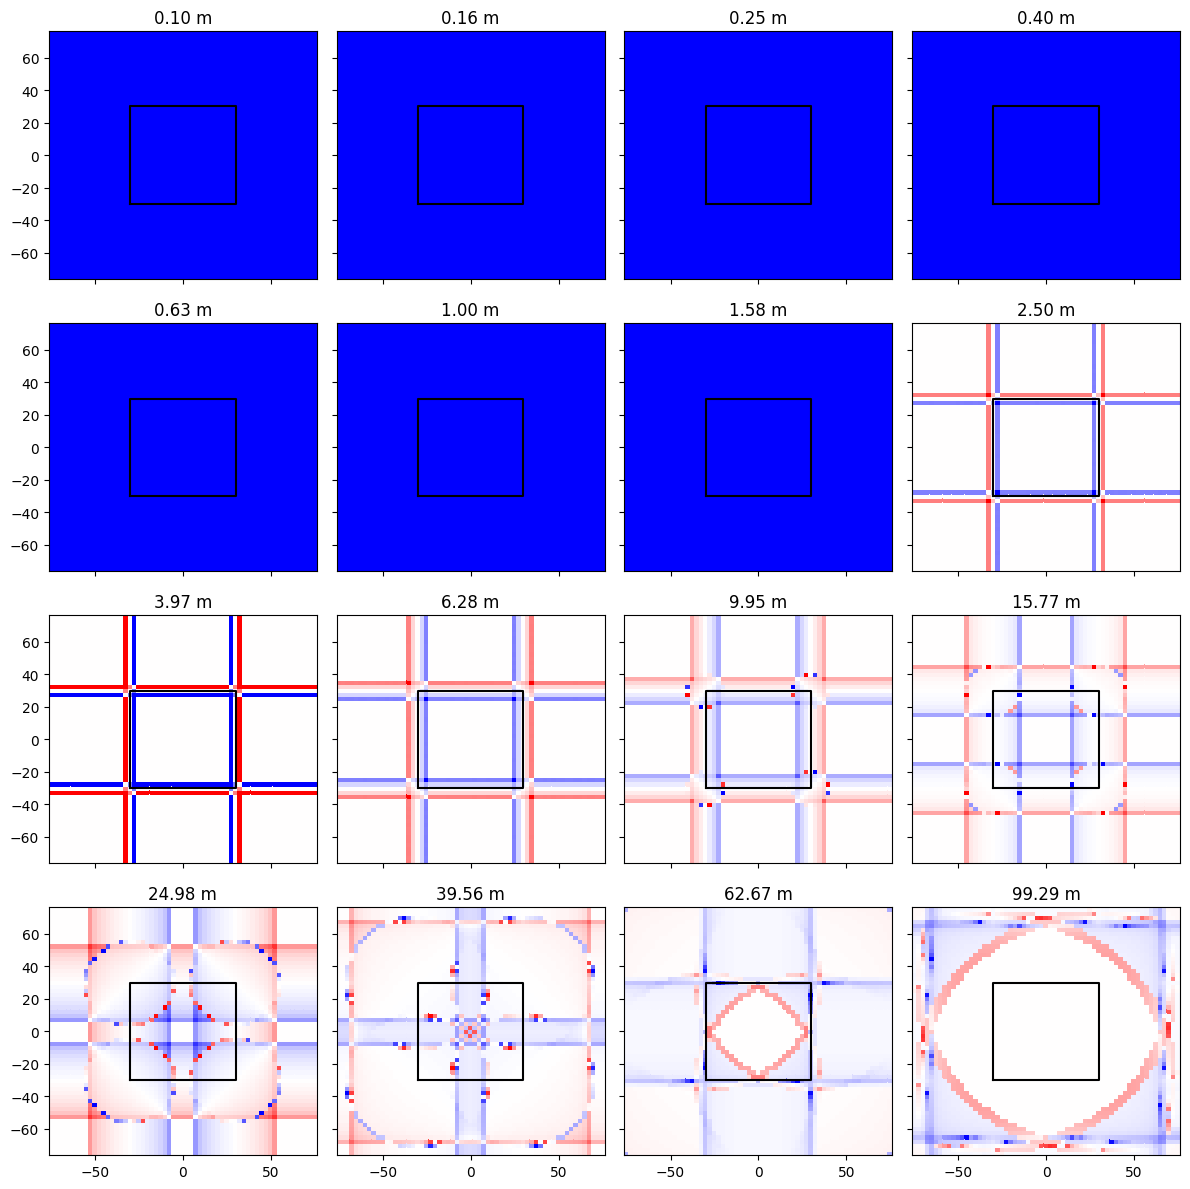

In [111]:
sofrcube = sofr.reshape(rxs.x.shape+r.shape)
fig,axs = plt.subplots(4,4, sharex=True, sharey=True, figsize=(12,12))
for i,ax in enumerate(axs.flatten()):
    ax.set_title(f'{r[i*n_skip]:0.2f} m')
    vlim = max(abs(sofrcube.real[:,:,i*n_skip].min()), abs(sofrcube.real[:,:,i*n_skip].max()))
    pcm=ax.pcolor(rxs.x, rxs.y, sofrcube.real[:,:,i*n_skip], vmin=-vlim, vmax=vlim, cmap='bwr')
    ax.plot(lp.x, lp.y, 'k')
# plt.colorbar(pcm, ax=axs, orientation='horizontal')
plt.tight_layout()
# plt.pcolor(rxs.x, rxs.y, np.abs(sofrcube[:,:,150]))

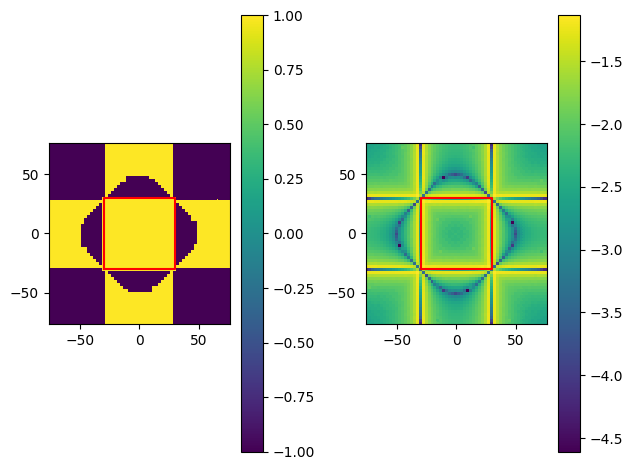

In [112]:
fig,axs=plt.subplots(1,2)
pcm=axs[0].pcolor(fwr3.receiver.x, fwr3.receiver.y, np.sign(bz))
axs[0].plot(lp.x, lp.y, 'r')
plt.colorbar(pcm, ax=axs[0])
axs[0].set_aspect(1)

pcm=axs[1].pcolor(fwr3.receiver.x, fwr3.receiver.y, np.log10(np.abs(bz)))
axs[1].plot(lp.x, lp.y, 'r')
plt.colorbar(pcm, ax=axs[1])
axs[1].set_aspect(1)
plt.tight_layout()
plt.show()

In [1651]:
len(rxs.x.flatten())

3721

In [1652]:
%matplotlib qt5
idx = len(rxs.x.flatten())//4
ridx = 90
fig,axs = plt.subplots(1,3)

idx_map = np.arange(len(rxs.x.flatten())).reshape(rxs.x.shape)

x_plc = rxs.x.flatten()[idx]
y_plc = rxs.y.flatten()[idx]

pcm=axs[0].pcolor(rxs.x, rxs.y, sofrcube.real[:,:,ridx], cmap='Greens')
axs[0].plot(lp.x, lp.y, 'k')
axs[0].plot(x_plc, y_plc, 'ro')
axs[0].set_title(f'{r[ridx]:0.2f} m')
axs[1].semilogx(r, sofr.real[idx,:])
axs[2].pcolor(rxs.x, rxs.y, idx_map, cmap='Greens')
plt.colorbar(pcm, ax=axs, orientation='horizontal')

In [1653]:
bz = fwr3(np.array([0.1, 0.1]), np.array([40]))[0].real.reshape(fwr3.receiver.shp[:-1])

C:\Users\au646858\AppData\Local\Temp\ipykernel_36984\493417930.py:2: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  R = torch.tensor(R, dtype=torch.float64)
